Итоговый проект по дисциплине «Автоматизация процессов разработки и тестирования моделей машинного обучения»

Разведочный анализ данных (EDA):

- Задача — PD-модель: оценить вероятность того, что клиент банка не внесет оплату по кредитной карте в следующем месяце.
- Цель EDA — проверить качество данных, найти признаки, связанные с дефолтом, и создать и обосновать новые признаки.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!ls "/content/drive/MyDrive/3семестр/pd-model/data/raw"

'default of credit card clients.xls'


In [3]:
!pip install xlrd

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
sns.set_theme(style="whitegrid")

In [5]:
#  Загрузка данных
PROJECT_DIR = "/content/drive/MyDrive/3семестр/pd-model"
DATA_PATH = PROJECT_DIR + "/data/raw/default of credit card clients.xls"

df = pd.read_excel(DATA_PATH, header=1)
df.shape

(30000, 25)

In [6]:
df.head(50)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,6,50000,1,1,2,37,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,7,500000,1,1,2,29,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
7,8,100000,2,2,2,23,0,-1,-1,0,...,221,-159,567,380,601,0,581,1687,1542,0
8,9,140000,2,3,1,28,0,0,2,0,...,12211,11793,3719,3329,0,432,1000,1000,1000,0
9,10,20000,1,3,2,35,-2,-2,-2,-2,...,0,13007,13912,0,0,0,13007,1122,0,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

Вывод:

Пропусков нет ни в одном столбце,все данные — целые числа, текста нет

In [8]:
# Целевая переменная (target), доля дефолтов в процентах
TARGET = "default payment next month"
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True))
print("Доля дефолтов:", round(df[TARGET].mean(), 4))

default payment next month
0    23364
1     6636
Name: count, dtype: int64
default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64
Доля дефолтов: 0.2212


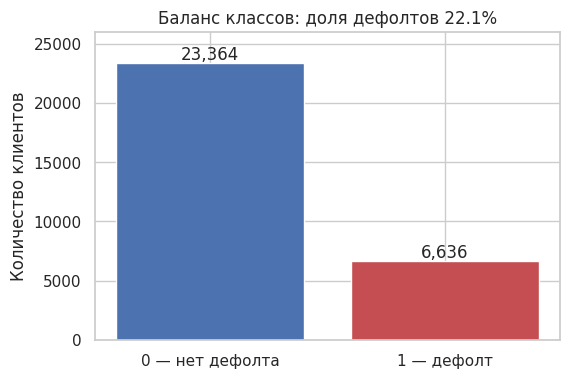

In [9]:
# График - баланс классов
fig, ax = plt.subplots(figsize=(6, 4))

counts = df[TARGET].value_counts().sort_index()
ax.bar(["0 — нет дефолта", "1 — дефолт"], counts.values, color=["#4c72b0", "#c44e52"])

ax.set_title(f"Баланс классов: доля дефолтов {df[TARGET].mean():.1%}")
ax.set_ylabel("Количество клиентов")

for i, v in enumerate(counts.values):
    ax.text(i, v + 300, f"{v:,}", ha="center")
ax.set_ylim(0, 26000)
plt.show()

Вывод:

- 23 364 клиента (77.9%) оплатили вовремя, 6 636 (22.1%) — допустили дефолт.
- Классы несбалансированы: «хороших» клиентов примерно в 3.5 раза больше. Модель, которая всем отвечает «дефолта не будет», окажется права в 78% случаев, но не найдёт ни одного должника. Поэтому accuracy не подходит — оцениваем по ROC-AUC, Precision, Recall и F1.
- При разбиении на train/test сохраняем долю дефолтов, а порог классификации подбираем отдельно(не берём 0.5).
- В данных нет столбца PAY_1(после PAY_0 сразу идёт PAY_2). Это особенность разметки датасета?

In [10]:
# Дубликаты строк (без учёта ID)
dups = df.drop(columns=["ID"]).duplicated().sum()
print("Дубликатов:", dups)
# Уникальность ID
print("ID уникален:", df["ID"].is_unique)
print("Уникальных ID:", df["ID"].nunique())

Дубликатов: 35
ID уникален: True
Уникальных ID: 30000


In [11]:
# Описательная статистика
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


Вывод:

В статистике были обнаружены следующие моменты:
1. Незадокументированные коды  некоторых категорий:
EDUCATION: min = 0, max = 6, а в описании только коды 1–4. Значит, в данных есть коды 0, 5 и 6.
MARRIAGE: min = 0. В описании только 1–3.
2. Коды PAY_* от -2 до 8
В описании:  -1 (оплатил вовремя), 1–8 (месяцы просрочки). А ещё есть -2(картой не пользовался) и 0(платит минимальный платёж). Т.е отрицательные значения — это не «отрицательная просрочка», а разные виды нормального поведения.
3. Отрицательные суммы счетов
BILL_AMT1 min = -165 580. Отрицательный счёт — это переплата: клиент заплатил больше, чем был должен, и банк должен ему(не ошибка данных).
4. Сильная асимметрия сумм
PAY_AMT2: медиана (50%) — 2 009, а максимум — 1 684 259. Среднее (5 921) почти в три раза выше медианы (у большинства клиентов платежи маленькие), а у небольшого количества  — огромные (выбросы).

In [12]:
# Распределение категориальных признаков
for col in ["EDUCATION", "MARRIAGE"]:
    print(col)
    print(df[col].value_counts().sort_index())
    print()
# Сколько клиентов с незадокументированными кодами
odd_edu = df["EDUCATION"].isin([0, 5, 6])
odd_mar = df["MARRIAGE"].isin([0])
odd_any = odd_edu | odd_mar

print("EDUCATION 0/5/6:", odd_edu.sum(), f"({odd_edu.mean():.2%})")
print("MARRIAGE 0:     ", odd_mar.sum(), f"({odd_mar.mean():.2%})")
print("Хотя бы один:   ", odd_any.sum(), f"({odd_any.mean():.2%})")

EDUCATION
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

EDUCATION 0/5/6: 345 (1.15%)
MARRIAGE 0:      54 (0.18%)
Хотя бы один:    399 (1.33%)


Вывод:

Таких клиентов немного: всего около 1.3% - удалять не будем, это реальные клиенты, объединим новые выявленные коды с группой «другое»:

1. в EDUCATION коды 0, 5 и 6 станут 4

2. в MARRIAGE код 0 станет 3.

сделаю на этапе  Feature Engineering, моделям будет проще обучаться



In [13]:
# Категориальные признаки: пол, образование, семейное положение
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    table = df.groupby(col)[TARGET].agg(["count", "mean"])
    table.columns = ["клиентов", "доля дефолтов"]
    print(col)
    print(table.round(3))
    print()

SEX
     клиентов  доля дефолтов
SEX                         
1       11888          0.242
2       18112          0.208

EDUCATION
           клиентов  доля дефолтов
EDUCATION                         
0                14          0.000
1             10585          0.192
2             14030          0.237
3              4917          0.252
4               123          0.057
5               280          0.064
6                51          0.157

MARRIAGE
          клиентов  доля дефолтов
MARRIAGE                         
0               54          0.093
1            13659          0.235
2            15964          0.209
3              323          0.260



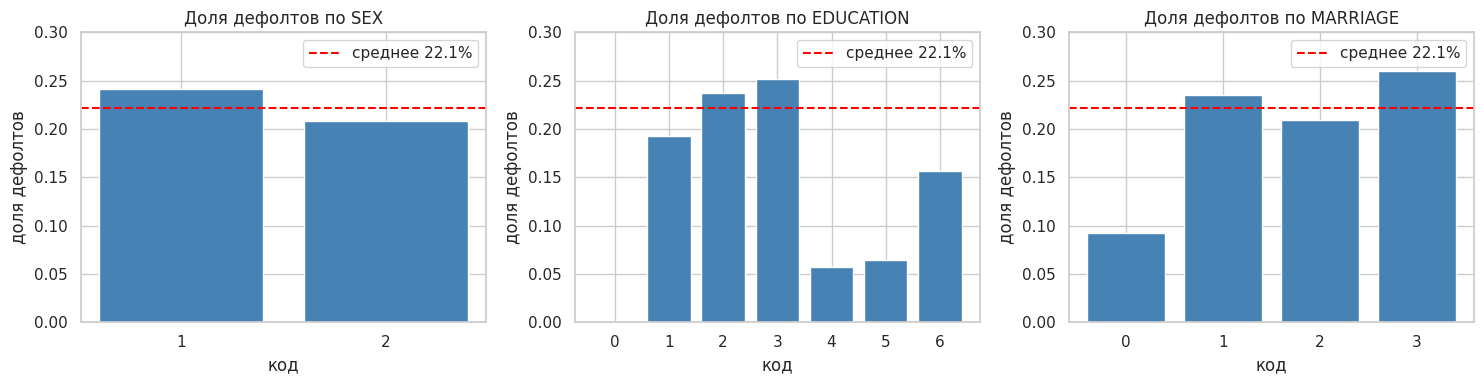

In [14]:
# Графики: доли дефолтов по признакам
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
avg = df[TARGET].mean()

for ax, col in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    rate = df.groupby(col)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color="steelblue")
    ax.axhline(avg, color="red", linestyle="--", label=f"среднее {avg:.1%}")
    ax.set_title(f"Доля дефолтов по {col}")
    ax.set_xlabel("код")
    ax.set_ylabel("доля дефолтов")
    ax.legend()
    ax.set_ylim(0, 0.3)
plt.tight_layout()
plt.show()

Вывод:

Отличается ли доля дефолтов в разных группах клиентов. Если да - признак полезен для модели.
Доля дефолтов по категориям (средняя — 22.1%)
- SEX: мужчины 24.2%, женщины 20.8% -слабое, но устойчивое различие.
- EDUCATION: риск растёт с понижением образования: 19.2% (магистратура) → 23.7% (университет) → 25.2% (школа).
  Коды 0/4/5/6 (468 клиентов) имеют низкий риск, около 7%.(можно объединять)
- MARRIAGE: в браке 23.5%, холостые 20.8%. Код 0 — всего 54 клиента, оценка ненадёжна; объединяем с «другое» (3).
Все три признака по отдельности слабые.

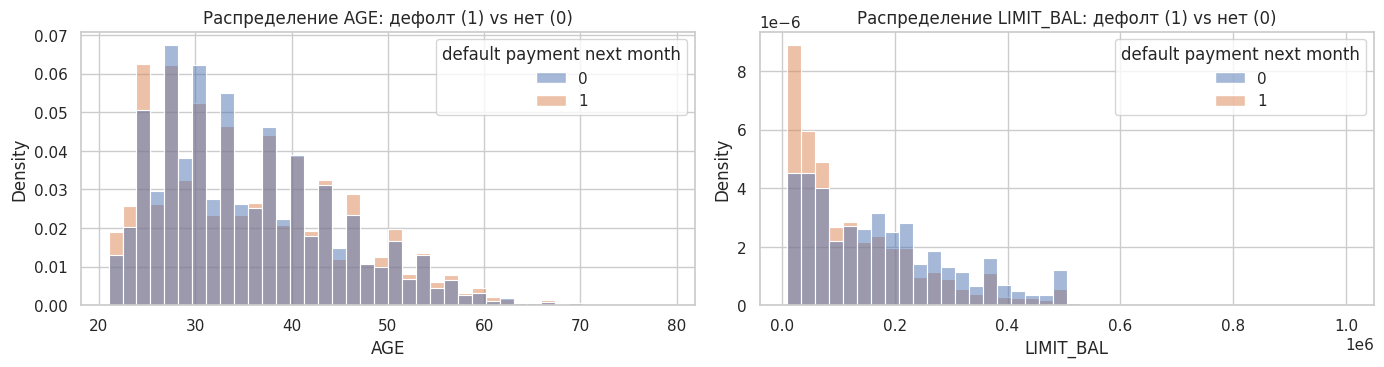

In [15]:
#Гистограммы AGE и LIMIT_BAL по классам
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, col in zip(axes, ["AGE", "LIMIT_BAL"]):
    sns.histplot(data=df, x=col, hue=TARGET, stat="density",
                 common_norm=False, bins=40, ax=ax)
    ax.set_title(f"Распределение {col}: дефолт (1) vs нет (0)")

plt.tight_layout()
plt.show()

Вывод:

Сравниваем распределения у клиентов с дефолтом и без: если они различаются, признак помогает отличить должников.
- LIMIT_BAL — заметный признак: должники сосредоточены при лимите до ~100 тыс., а при лимите от 150 тыс.
  преобладают надёжные клиенты.
- AGE — слабый признак: распределения почти совпадают, риск немного выше у молодых (до 25) и старших (45+).
  Зависимость нелинейная, поэтому делаем биннинг возраста — разбиваем на группы.

         клиенты  доля дефолтов
AGE_BIN                        
21-25       3871          0.267
26-30       7142          0.201
31-35       5796          0.194
36-40       4917          0.216
41-50       6005          0.233
51-60       1997          0.252
61+          272          0.268


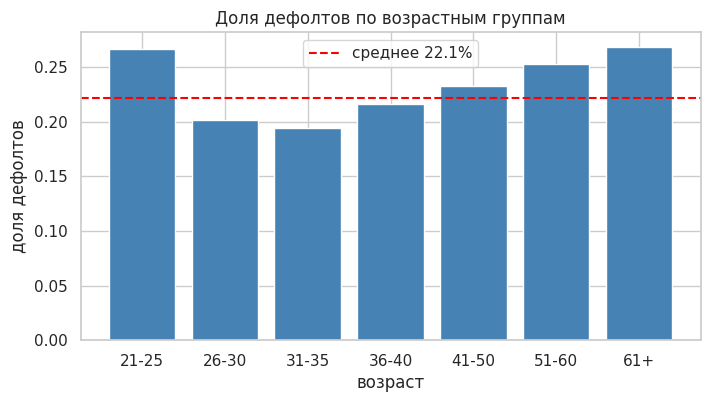

In [16]:
# Биннинг
bins = [20, 25, 30, 35, 40, 50, 60, 80]
labels = ["21-25", "26-30", "31-35", "36-40", "41-50", "51-60", "61+"]

df["AGE_BIN"] = pd.cut(df["AGE"], bins=bins, labels=labels)

age_table = df.groupby("AGE_BIN", observed=True)[TARGET].agg(["count", "mean"])
age_table.columns = ["клиенты", "доля дефолтов"]
print(age_table.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(age_table.index.astype(str), age_table["доля дефолтов"], color="steelblue")
ax.axhline(avg, color="red", linestyle="--", label=f"среднее {avg:.1%}")
ax.set_title("Доля дефолтов по возрастным группам")
ax.set_xlabel("возраст")
ax.set_ylabel("доля дефолтов")
ax.legend()
plt.show()

 Вывод:

Биннинг возраста:

Разбили возраст на 7 групп: до 40 лет — по 5 лет, старше — по 10, чтобы в каждой группе было достаточно клиентов.
- Риск выше среднего (22.1%) у молодых (21–25 лет, 26.7%) и старших (51+, 25–27%), ниже всего — в 26–35 лет (~20%).
- Риск меняется по возрасту неравномерно: сначала снижается, потом растёт. По группам модель учтёт это лучше,
  чем по возрасту в годах, поэтому AGE_BIN добавляем в Feature Engineering.
- Группа 61+ маленькая (272 клиента), её оценка менее надёжна.

       клиенты  доля дефолтов
PAY_0                        
-2        2759          0.132
-1        5686          0.168
 0       14737          0.128
 1        3688          0.339
 2        2667          0.691
 3         322          0.758
 4          76          0.684
 5          26          0.500
 6          11          0.545
 7           9          0.778
 8          19          0.579


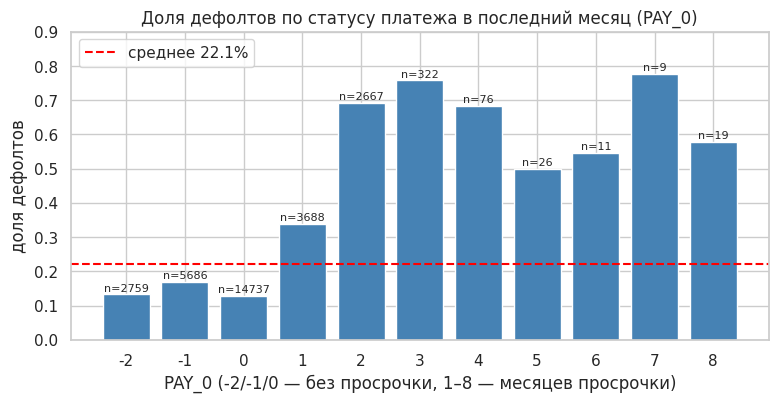

In [17]:
# История платежей (PAY_0 … PAY_6)
pay_table = df.groupby("PAY_0")[TARGET].agg(["count", "mean"])
pay_table.columns = ["клиенты", "доля дефолтов"]
print(pay_table.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(pay_table.index.astype(str), pay_table["доля дефолтов"], color="steelblue")
ax.axhline(avg, color="red", linestyle="--", label=f"среднее {avg:.1%}")
ax.set_title("Доля дефолтов по статусу платежа в последний месяц (PAY_0)")
ax.set_xlabel("PAY_0 (-2/-1/0 — без просрочки, 1–8 — месяцев просрочки)")
ax.set_ylabel("доля дефолтов")
ax.legend()
for i, n in enumerate(pay_table["клиенты"]):
    ax.text(i, pay_table["доля дефолтов"].iloc[i] + 0.01, f"n={n}", ha="center", fontsize=8)
ax.set_ylim(0, 0.9)
plt.show()

Вывод:

PAY_0 — статус платежа за последний месяц (сентябрь), PAY_2…PAY_6 — более ранние месяцы.
Коды: −2 — не пользовался картой, −1 — оплатил полностью, 0 — внёс минимальный платёж,
1…8 — просрочка на столько месяцев.

- Без просрочки (−2/−1/0) риск 13–17%, ниже среднего (22.1%).
- Просрочка 1 месяц — 34%, 2 месяца и более — около 70%, почти втрое выше среднего.
- Значения 4–8 встречаются редко (от 9 до 76 клиентов), поэтому их доли шумные.
- Недавняя просрочка — главный сигнал будущего дефолта, признаки PAY_* будут ключевыми в модели.

          клиенты  доля дефолтов
N_DELAYS                        
0           19931          0.117
1            4426          0.298
2            1899          0.388
3            1154          0.509
4             951          0.573
5             298          0.574
6            1341          0.703


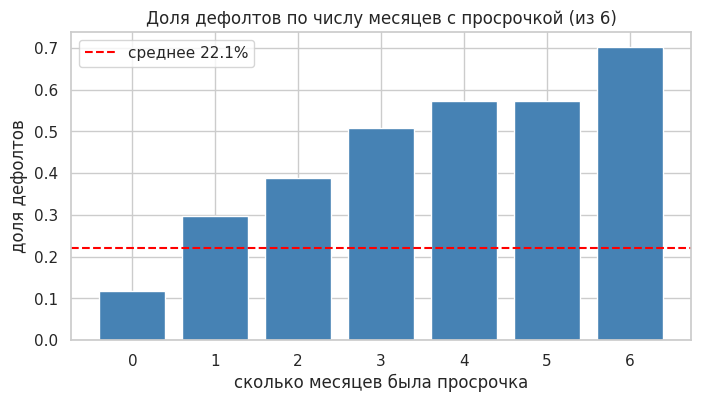

In [18]:
# Новый признак: сколько месяцев из 6 была просрочка
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

df["N_DELAYS"] = (df[pay_cols] > 0).sum(axis=1)

delay_table = df.groupby("N_DELAYS")[TARGET].agg(["count", "mean"])
delay_table.columns = ["клиенты", "доля дефолтов"]
print(delay_table.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(delay_table.index.astype(str), delay_table["доля дефолтов"], color="steelblue")
ax.axhline(avg, color="red", linestyle="--", label=f"среднее {avg:.1%}")
ax.set_title("Доля дефолтов по числу месяцев с просрочкой (из 6)")
ax.set_xlabel("сколько месяцев была просрочка")
ax.set_ylabel("доля дефолтов")
ax.legend()
plt.show()

In [19]:
has_delay = df["N_DELAYS"] > 0

n_delay = has_delay.sum()
share_clients = has_delay.mean()
risk_delay = df.loc[has_delay, TARGET].mean()
risk_no_delay = df.loc[~has_delay, TARGET].mean()
share_defaults = df.loc[has_delay, TARGET].sum() / df[TARGET].sum()

print(f"Клиент с хотя бы одной просрочкой: {n_delay} ({share_clients:.1%} выборки)")
print(f"Риск дефолта у них:                  {risk_delay:.1%}")
print(f"Риск дефолта без просрочек:          {risk_no_delay:.1%}")
print(f"Доля всех дефолтов:                  {share_defaults:.1%}")

Клиент с хотя бы одной просрочкой: 10069 (33.6% выборки)
Риск дефолта у них:                  42.7%
Риск дефолта без просрочек:          11.7%
Доля всех дефолтов:                  64.8%


Вывод:

- Новый признак N_DELAYS — число месяцев с просрочкой (из 6)
  Создали агрегат по истории платежей: для каждого клиента посчитали, в скольких месяцах из 6 статус платежа показывал просрочку (PAY > 0). Например, статусы [2, 1, 0, −1, 0, 2] → просрочка в 3 месяцах → N_DELAYS = 3.
- Риск растёт монотонно: 0 просрочек — 11.7%, 1 — 29.8%, 3 — 50.9%, 6 — 70.3%.
- Клиенты хотя бы с одной просрочкой — 33.6% выборки (10 069) - их риск 42.7% против 11.7% у клиентов без просрочек (в 3.6 раза выше).На эту треть клиентов приходится 64.8% всех дефолтов.
- Признак учитывает всю историю, а не один месяц, и даёт устойчивые оценки (все группы ≥ 298 клиентов).
- Добавлю N_DELAYS в Feature Engineering.

count    30000.000
mean         0.424
std          0.411
min         -0.620
25%          0.022
50%          0.314
75%          0.830
max          6.455
Name: UTIL, dtype: float64
                   клиентов  доля дефолтов
UTIL_BIN                                  
(-0.621, 0.00124]      3000          0.241
(0.00124, 0.0113]      3002          0.196
(0.0113, 0.0405]       2998          0.157
(0.0405, 0.131]        3000          0.148
(0.131, 0.314]         3000          0.178
(0.314, 0.524]         3000          0.224
(0.524, 0.736]         3000          0.264
(0.736, 0.902]         3000          0.279
(0.902, 0.982]         3000          0.238
(0.982, 6.455]         3000          0.286


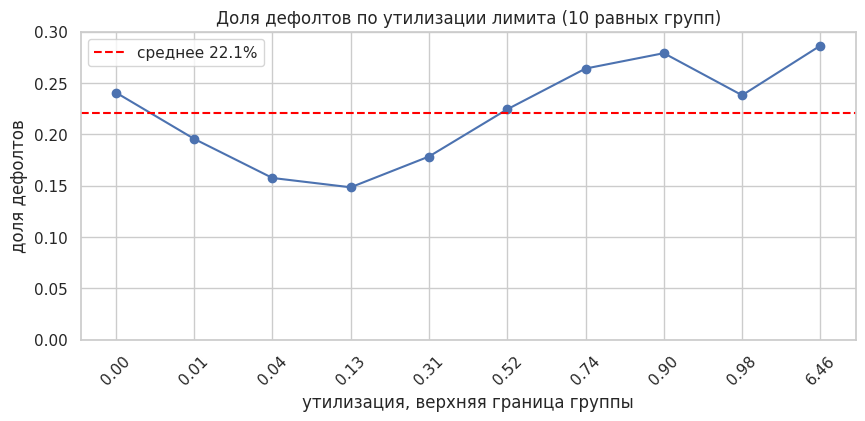

In [20]:
# Какая доля кредитного лимита использована (долг / лимит)
df["UTIL"] = df["BILL_AMT1"] / df["LIMIT_BAL"]
print(df["UTIL"].describe().round(3))

df["UTIL_BIN"] = pd.qcut(df["UTIL"], q=10, duplicates="drop")
util_table = df.groupby("UTIL_BIN", observed=True)[TARGET].agg(["count", "mean"])
util_table.columns = ["клиентов", "доля дефолтов"]
print(util_table.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(util_table)), util_table["доля дефолтов"], marker="o")
ax.axhline(avg, color="red", linestyle="--", label=f"среднее {avg:.1%}")
ax.set_xticks(range(len(util_table)))
ax.set_xticklabels([f"{b.right:.2f}" for b in util_table.index], rotation=45)
ax.set_title("Доля дефолтов по утилизации лимита (10 равных групп)")
ax.set_xlabel("утилизация, верхняя граница группы")
ax.set_ylabel("доля дефолтов")
ax.legend()
ax.set_ylim(0, 0.3)
plt.show()

Вывод:

утилизация лимита UTIL = BILL_AMT1 / LIMIT_BAL
Утилизация показывает, какая доля кредитного лимита использована (долг 45 000 при лимите 50 000 → 0.9).
В отличие от суммы долга, она делает клиентов с разными лимитами сравнимыми.
Разбили клиентов на 10 равных групп (по 3000).

- Зависимость нелинейная: риск ниже всего (15%) при утилизации 1–13%, выше — у клиентов
  без долга (24%) и максимальный (28%) при исчерпанном лимите.
- Отрицательные значения — переплата, утилизация выше 1 — превышение лимита (редкие случаи).
- Признак слабее истории просрочек (риск меняется в диапазоне 15–29% против 12–70% у N_DELAYS), но полезен. Из-за нелинейности ожидаем преимущество у деревьев и бустинга.
- Добавлю UTIL в Feature Engineering.

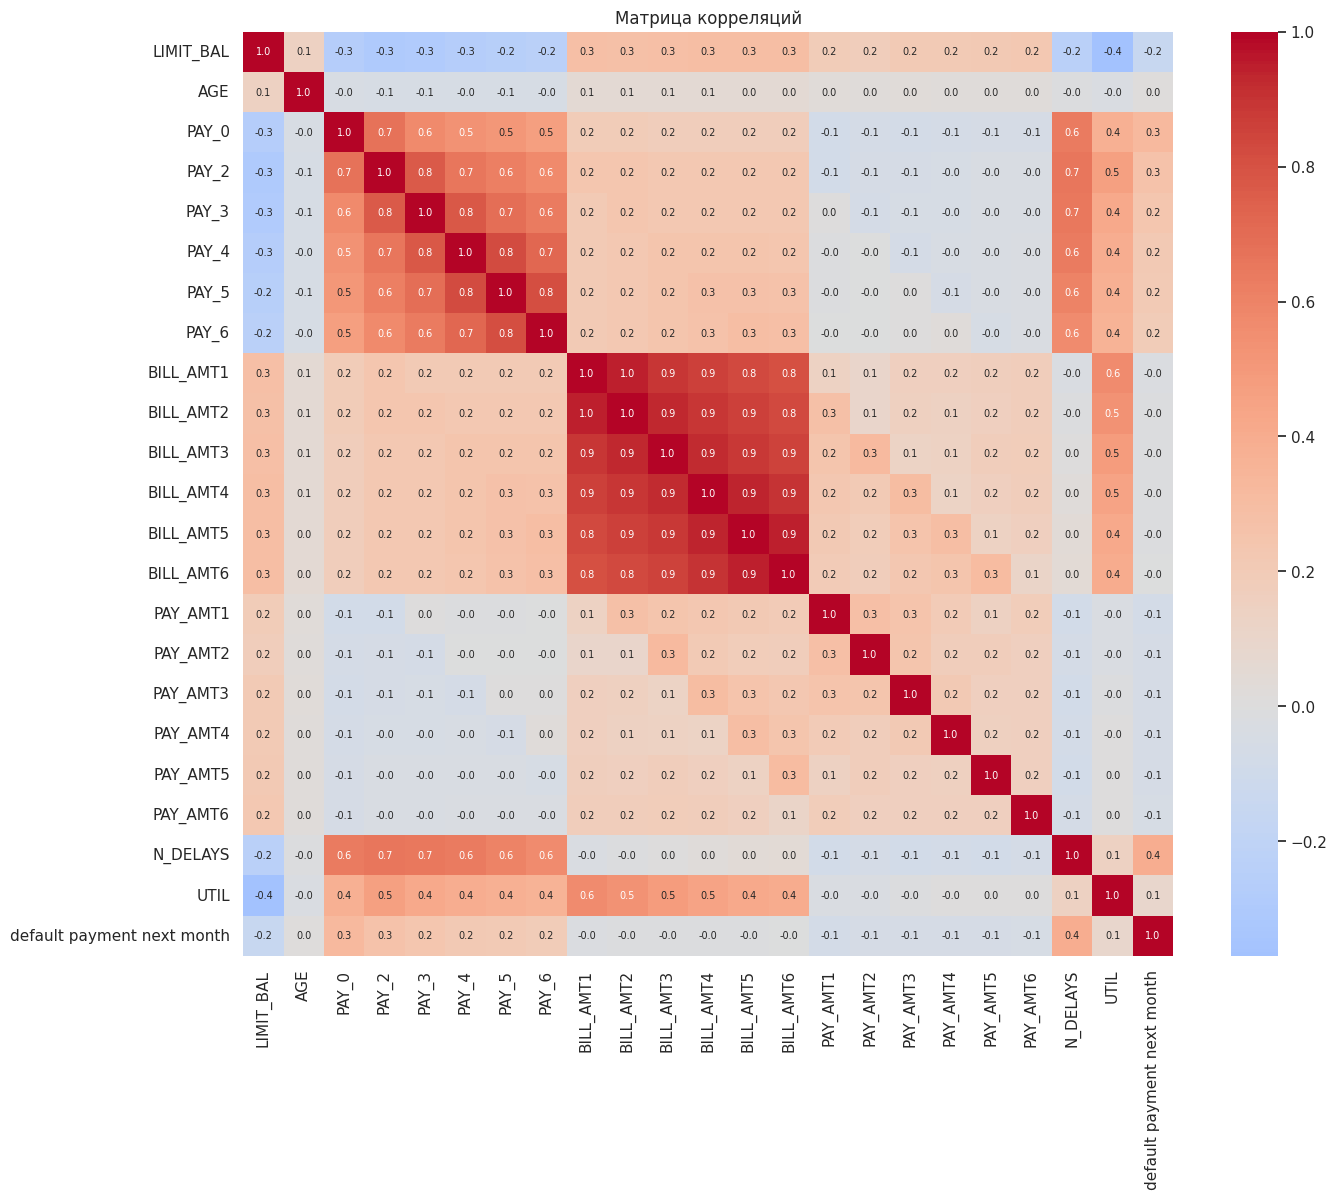

In [21]:
# Корреляции между признаками
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
num_cols = ["LIMIT_BAL", "AGE"] + pay_cols + bill_cols + amt_cols + ["N_DELAYS", "UTIL", TARGET]

corr = df[num_cols].corr()
# Тепловая карта корреляций
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Матрица корреляций")
fig.savefig(PROJECT_DIR + "/reports/figures/corr_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Вывод: корреляции

Связь с дефолтом: сильнее всего — N_DELAYS (0.4), PAY_0 и PAY_2 (0.3), LIMIT_BAL (−0.2).
BILL_AMT и AGE почти не связаны с дефолтом (≈ 0).

- Корреляция измеряет только линейную связь. У AGE и UTIL она ≈ 0, хотя по группам риск заметно различается (зависимость нелинейная). Поэтому признаки оцениваем ещё и по IV.
- Дублирующие признаки (мультиколлинеарность): BILL_AMT1…6 почти одинаковы (0.8–1.0),
PAY_* сильно связаны между собой (0.5–0.8).
- Для логистической регрессии это решаем регуляризацией, деревья к этому устойчивы.
- Вместо шести BILL_AMT используем агрегаты: утилизацию и среднюю утилизацию.

In [22]:
# Рейтинг признаков по связи с дефолтом
target_corr = corr[TARGET].drop(TARGET)
target_corr = target_corr.sort_values(key=abs, ascending=False)
print(target_corr.round(3))

N_DELAYS     0.398
PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
UTIL         0.086
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
PAY_AMT3    -0.056
PAY_AMT5    -0.055
PAY_AMT6    -0.053
BILL_AMT1   -0.020
BILL_AMT2   -0.014
BILL_AMT3   -0.014
AGE          0.014
BILL_AMT4   -0.010
BILL_AMT5   -0.007
BILL_AMT6   -0.005
Name: default payment next month, dtype: float64


Вывод:

Какие признаки сильнее всего связаны с дефолтом:
- Самые сильные — просрочки:число месяцев с просрочкой (N_DELAYS) и статус последних платежей (PAY_0, PAY_2).
- Свежие данные важнее старых: просрочка в прошлом месяце связана с дефолтом сильнее, чем полгода назад.
- Больше лимит — меньше риск (LIMIT_BAL).
- Суммы платежей связаны слабо, а суммы долга и возраст — почти никак.
- Корреляция видит только прямую связь, поэтому дальше проверяем признаки ещё и через Information Value.

In [23]:
# Information Value(IV)
def calc_iv(data, col, bins=10):
    x = data[col]
    if x.nunique() > bins:
        x = pd.qcut(x, q=bins, duplicates="drop")
    t = pd.crosstab(x, data[TARGET])
    good = (t[0] + 0.5) / t[0].sum()
    bad = (t[1] + 0.5) / t[1].sum()
    woe = np.log(good / bad)
    return ((good - bad) * woe).sum()

features = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", "AGE_BIN"] \
           + pay_cols + bill_cols + amt_cols + ["N_DELAYS", "UTIL"]

iv = pd.Series({col: calc_iv(df, col) for col in features}).sort_values(ascending=False)

iv_table = pd.DataFrame({
    "IV": iv.round(3),
    "сила": pd.cut(iv, bins=[0, 0.02, 0.1, 0.3, 0.5, np.inf],
                   labels=["бесполезный", "слабый", "средний", "сильный", "очень сильный"])
})
print(iv_table)

              IV           сила
PAY_0      0.870  очень сильный
N_DELAYS   0.862  очень сильный
PAY_2      0.542  очень сильный
PAY_3      0.411        сильный
PAY_4      0.359        сильный
PAY_5      0.341        сильный
PAY_6      0.294        средний
LIMIT_BAL  0.178        средний
PAY_AMT1   0.161        средний
PAY_AMT2   0.147        средний
PAY_AMT3   0.123        средний
PAY_AMT6   0.090         слабый
PAY_AMT4   0.090         слабый
PAY_AMT5   0.081         слабый
UTIL       0.077         слабый
EDUCATION  0.038         слабый
AGE        0.021         слабый
AGE_BIN    0.020         слабый
BILL_AMT6  0.019    бесполезный
BILL_AMT5  0.014    бесполезный
BILL_AMT1  0.012    бесполезный
BILL_AMT2  0.011    бесполезный
BILL_AMT4  0.011    бесполезный
BILL_AMT3  0.010    бесполезный
SEX        0.009    бесполезный
MARRIAGE   0.007    бесполезный


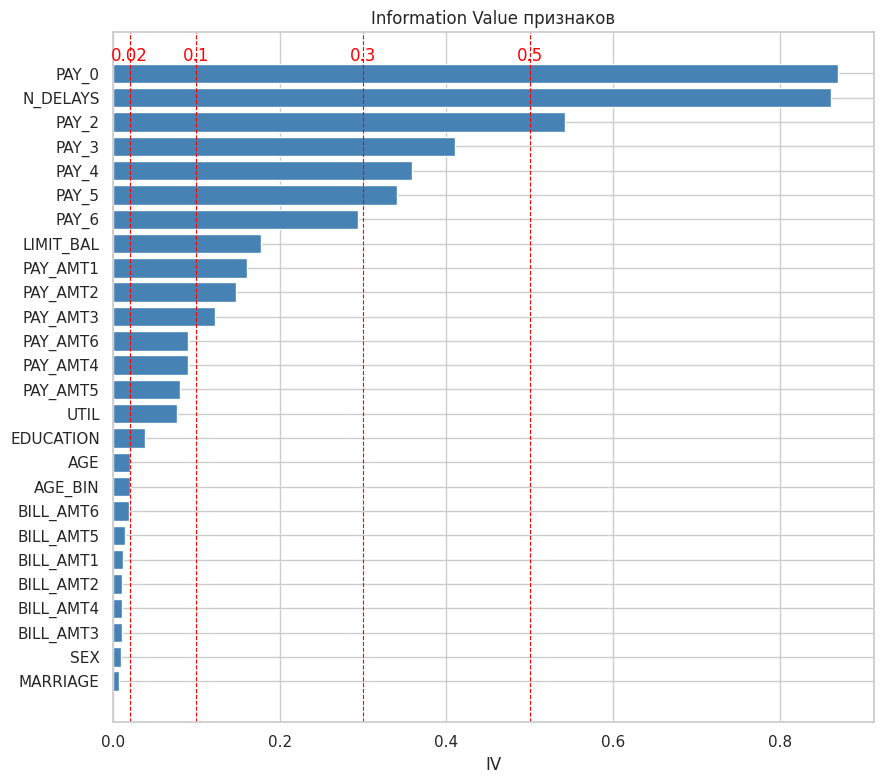

In [24]:
# График Information Value
fig, ax = plt.subplots(figsize=(9, 8))
iv_sorted = iv.sort_values()
ax.barh(iv_sorted.index, iv_sorted.values, color="steelblue")
for x, name in [(0.02, "0.02"), (0.1, "0.1"), (0.3, "0.3"), (0.5, "0.5")]:
    ax.axvline(x, color="red", linestyle="--", linewidth=0.8)
    ax.text(x, len(iv_sorted) - 0.5, name, color="red", ha="center")
ax.set_title("Information Value признаков")
ax.set_xlabel("IV")
plt.tight_layout()
fig.savefig(PROJECT_DIR + "/reports/figures/iv.png", dpi=150, bbox_inches="tight")
plt.show()

Вывод:

- Сильнее всего предсказывают дефолт статус последних платежей (PAY_0, IV 0.87) и наш признак N_DELAYS (0.86).
  N_DELAYS получился таким же сильным, как лучший исходный признак.
- Утечки данных нет: PAY_0 — это статус за сентябрь, а предсказываем платёж в октябре.
  На момент прогноза сентябрьский статус уже известен.
- IV нашёл то, что не заметила корреляция: у суммы последнего платежа (PAY_AMT1) корреляция почти нулевая,
  а IV средний (0.16), т.е. связь есть, но нелинейная.
- Суммы долга (BILL_AMT), пол и семейное положение почти ничего не дают (IV < 0.02).
  При этом из суммы долга получился полезный признак — утилизация (IV 0.077).
- Пол можно убрать из модели: информации в нём почти нет, а использовать пол в кредитном скоринге
  во многих странах запрещено.

In [25]:
#  Дополнительные агрегаты платежей
df["N_ZERO_PAY"] = (df[amt_cols] == 0).sum(axis=1)
df["PAY_AMT_MEAN"] = df[amt_cols].mean(axis=1)
df["UTIL_MEAN"] = df[bill_cols].mean(axis=1) / df["LIMIT_BAL"]

for col in ["N_ZERO_PAY", "PAY_AMT_MEAN", "UTIL_MEAN"]:
    print(col, round(calc_iv(df, col), 3))

N_ZERO_PAY 0.263
PAY_AMT_MEAN 0.191
UTIL_MEAN 0.129


Вывод: дополнительные агрегаты платежей

Создали ещё три признака, которые описывают поведение клиента за полгода, а не за один месяц:
- N_ZERO_PAY — в скольких месяцах из 6 клиент ничего не заплатил (IV 0.26);
- PAY_AMT_MEAN — средний платёж за 6 месяцев (IV 0.19);
- UTIL_MEAN — средняя доля лимита, занятая долгом за 6 месяцев (IV 0.13).

Все три сильнее исходных признаков: у отдельных платежей IV не выше 0.16, у сумм долга — меньше 0.02.
Один месяц может быть случайностью, а поведение за полгода показывает устойчивую картину.
Добавляю эти признаки в Feature Engineering.


Главные выводы:
1. Лучше всего дефолт предсказывает история просрочек. Без просрочки в последнем месяце риск 13–17%,
   при просрочке от 2 месяцев — около 70% (IV PAY_0 = 0.87).
2. Свежие данные важнее старых: сила признака падает от последнего месяца к самому раннему (IV с 0.87 до 0.29).
3. Чем больше кредитный лимит, тем ниже риск; должники сосредоточены при лимите до ~100 тыс. (IV 0.18).
4. Часть зависимостей нелинейная: риск по возрасту и утилизации сначала снижается, а потом растёт.
   Корреляция такие связи недооценивает, поэтому ожидаем, что деревья и бустинг будут работать лучше
   логистической регрессии.
5. Суммы долга, пол и семейное положение сами по себе почти не влияют на дефолт (IV < 0.02).
6. Суммы долга за разные месяцы почти дублируют друг друга, платёжные статусы тоже сильно связаны.
   Для логистической регрессии это решается регуляризацией.

**Новые признаки (Feature Engineering, `src/features/build_features.py`).**

| Признак | Что это | IV |
|---|---|---|
| EDUCATION, MARRIAGE | редкие коды объединены с «другое» | — |
| AGE_BIN | возраст, разбитый на 7 групп | 0.020 |
| N_DELAYS | число месяцев с просрочкой (из 6) | 0.862 |
| N_ZERO_PAY | число месяцев без платежа (из 6) | 0.263 |
| PAY_AMT_MEAN | средний платёж за 6 месяцев | 0.191 |
| UTIL_MEAN | средняя доля лимита, занятая долгом за 6 месяцев | 0.129 |
| UTIL | доля лимита, занятая долгом в последнем месяце | 0.077 |

Новые признаки сильнее исходных, из которых построены: у отдельных платежей IV не выше 0.16, у сумм долга — меньше 0.02.